In [ ]:
%pip install puremacro


# Módulo 4 — RBC: momentos, Slutsky y el reto de México

**Curso complementario · puremacro**

### Objetivos de aprendizaje
Al terminar esta lección podrás:
1. Construir la **tabla de momentos del ciclo** (volatilidades relativas, comovimiento,
   persistencia) con el filtro de **Hamilton** sobre datos reales de EE. UU.
2. Entender el **efecto Slutsky**: una media móvil de ruido blanco fabrica un ciclo que
   a simple vista no se distingue del ciclo real.
3. Contrastar el RBC canónico con el **reto mexicano**, enunciado como toca: no que
   $\sigma_c/\sigma_y$ cruce el $1$ —con la convención canónica del curso **no lo cruza**—
   sino que esté *tan pegado* al $1$ cuando el modelo cerrado, **medido con la misma
   ficha que los datos**, queda muy abajo. Es un fallo de **magnitud**, no de signo. Y
   repasar sus tres salidas: choques de productividad más grandes o más persistentes,
   choques a la **tendencia**, y la **tasa de interés país** ($q_t$).

Todo corre en Python puro sobre tu **instalación local** de `puremacro`
(`pip install puremacro`): sin conexión y sin costo.

In [1]:
import sys, pathlib
import numpy as np, pandas as pd
import matplotlib
try:  # bajo Jupyter/ipykernel: conserva el backend inline (captura figuras)
    get_ipython()
except NameError:
    matplotlib.use("Agg")  # script plano / CLI: backend no interactivo
import matplotlib.pyplot as plt
_here = pathlib.Path(__file__).resolve().parent if "__file__" in globals() else pathlib.Path.cwd()
_nb = _here if (_here / "_nbstyle.py").exists() else (_here.parent if (_here.parent / "_nbstyle.py").exists() else _here)
sys.path.insert(0, str(_nb)); sys.path.insert(0, str(_nb / "course"))
import _nbstyle; _nbstyle.apply_style()
from _tutor import tutor
DATA = (_here / "data") if (_here / "data").exists() else (_nb / "course" / "data")

## 1. Los momentos del ciclo económico

El modelo de **ciclos económicos reales** (RBC) se juzga por su capacidad de reproducir
un puñado de *momentos*: la **desviación estándar** del producto, las **volatilidades
relativas** de sus componentes ($\sigma_x/\sigma_y$), el **comovimiento** de cada
componente con el producto y la **persistencia** (autocorrelación de primer orden) del
ciclo. Antes de calcularlos hay que separar tendencia y ciclo; aquí usamos el filtro de
**Hamilton (2018)**, que proyecta $y_{t+h}$ sobre sus rezagos recientes y toma el residuo
como ciclo (evita las dinámicas espurias del filtro HP).

Datos reales del *bundle*: `GDPC1` (PIB real) y `GPDIC1` (inversión **privada bruta
interna**, que incluye la variación de existencias), ambos trimestrales; la celda imprime
la muestra.

In [2]:
from puremacro.cycles import hamilton_filter
from puremacro.data import hp_filter
from puremacro.spectral import business_cycle_band_power

y = pd.read_csv(DATA / "GDPC1.csv")
inv = pd.read_csv(DATA / "GPDIC1.csv")
panel = y.merge(inv, on="observation_date")
_trim = pd.PeriodIndex(pd.to_datetime(panel["observation_date"]), freq="Q")
print(f"muestra: {_trim[0]}–{_trim[-1]} ({len(panel)} trimestres)")

log_y = 100.0 * np.log(panel["GDPC1"].to_numpy())     # log-PIB en puntos porcentuales
log_i = 100.0 * np.log(panel["GPDIC1"].to_numpy())    # log-inversión

cyc_y, _ = hamilton_filter(log_y)   # (ciclo, tendencia); las primeras h+p-1 obs son NaN
cyc_i, _ = hamilton_filter(log_i)

ok = ~np.isnan(cyc_y) & ~np.isnan(cyc_i)              # descartar el calentamiento del filtro
cyc_y, cyc_i = cyc_y[ok], cyc_i[ok]

muestra: 1947Q1–2026Q1 (317 trimestres)


### La tabla de momentos
Sobre el ciclo de Hamilton: volatilidad absoluta del producto, volatilidad relativa de la
inversión ($\sigma_i/\sigma_y$), su comovimiento con el producto, la persistencia del PIB
y la cuota de varianza que cae en la banda de negocios de 6–32 trimestres.

In [3]:
sigma_y = cyc_y.std()
rel_vol_inv = cyc_i.std() / sigma_y
comov_inv = np.corrcoef(cyc_i, cyc_y)[0, 1]
persist_y = np.corrcoef(cyc_y[1:], cyc_y[:-1])[0, 1]
band_share = business_cycle_band_power(cyc_y)

print(f"observaciones usadas                       = {cyc_y.size}")
print(f"sigma_y  (desv. est. del ciclo del PIB, %) = {sigma_y:.2f}")
print(f"sigma_i / sigma_y  (volatilidad relativa)  = {rel_vol_inv:.2f}")
print(f"comovimiento  corr(inversión, PIB)         = {comov_inv:.2f}")
print(f"persistencia  corr(y_t, y_t-1)             = {persist_y:.2f}")
print(f"cuota espectral en banda 6-32 trimestres   = {band_share:.2f}")

# Hechos canónicos: la inversión es mucho más volátil que el producto y muy procíclica.
assert rel_vol_inv > 2.0
assert comov_inv > 0.6
assert 0.0 < band_share <= 1.0

observaciones usadas                       = 306
sigma_y  (desv. est. del ciclo del PIB, %) = 3.25
sigma_i / sigma_y  (volatilidad relativa)  = 3.81
comovimiento  corr(inversión, PIB)         = 0.82
persistencia  corr(y_t, y_t-1)             = 0.89
cuota espectral en banda 6-32 trimestres   = 0.63


**Lectura.** La inversión es $3.81$ veces más volátil que el producto y fuertemente
procíclica ($0.82$); el producto es muy persistente ($0.89$). Estos son justo los blancos
que un RBC bien calibrado debe acertar.

*Aviso de comparabilidad con el mazo A4.* Antes de comparar este $3.81$ con la tabla del
mazo, revisa qué serie de inversión usa cada uno. `GPDIC1` es inversión privada bruta
**con existencias**, y la variación de existencias es el componente más volátil de la
contabilidad nacional; un agregado unisectorial o la inversión fija privada son otras
series y dan otro cociente. Cifras distintas para series distintas no se contradicen: es
exactamente el punto de la ficha de medición de la parte 3.

El componente que *falta* aquí es el **consumo**: en EE. UU. es
más suave que el producto ($\sigma_c/\sigma_y<1$), el rasgo que la hipótesis de renta
permanente predice. La pregunta de la parte 3 es **cuánto** más suave, y contra qué vara:
ahí es donde México y el RBC canónico se separan.

## 2. El ciclo que fabrica el azar (efecto Slutsky)

Slutsky (1927) mostró algo incómodo: si tomas **ruido blanco** —puro azar, sin ninguna
estructura cíclica— y lo pasas por una **media móvil**, aparecen ondas suaves y
recurrentes que *parecen* un ciclo económico. La suma de choques independientes,
promediada, induce persistencia y ondulación de la nada. La pregunta filosa: ¿podemos
distinguir ese ciclo espurio del ciclo real del PIB?

In [4]:
SEMILLA = 20260721                      # datos SIMULADOS: ruido blanco (declarado)
T = cyc_y.size
k = 8                                   # ventana de la media móvil, en trimestres (= el mazo A4)
# Pedimos T+k-1 innovaciones y convolucionamos en modo "valid": así la media móvil tiene
# exactamente T observaciones y NINGUNA está contaminada por los bordes. Con mode="same"
# las primeras y últimas k/2 serían sumas parciales divididas por k, artificialmente planas.
rng = np.random.default_rng(SEMILLA)
ruido = rng.standard_normal(T + k - 1)               # ruido blanco iid
ma = np.convolve(ruido, np.ones(k) / k, mode="valid")
ma = ma / ma.std()                                   # normalizar a varianza 1
cyc_y_norm = cyc_y / cyc_y.std()                     # ciclo real normalizado, para comparar
assert ma.size == T

persist_ma = np.corrcoef(ma[1:], ma[:-1])[0, 1]
band_ruido = business_cycle_band_power(ruido)
band_ma = business_cycle_band_power(ma)
ancho_banda = (1 / 6 - 1 / 32) / 0.5                 # fracción de [0, 0.5] ciclos/trimestre
print(f"persistencia  ciclo real del PIB           = {persist_y:.2f}")
print(f"persistencia  media móvil de ruido blanco  = {persist_ma:.2f}")
print(f"banda 6-32t   ruido blanco crudo           = {band_ruido:.2f}"
      f"   (ancho relativo de la banda = {ancho_banda:.2f})")
print(f"banda 6-32t   media móvil de ruido blanco  = {band_ma:.2f}")
print(f"banda 6-32t   ciclo real del PIB           = {band_share:.2f}")

# La ventana k fija el "periodo" del ciclo fabricado: repetimos con k = 20 (mismo ruido base).
k_largo = 20
ruido_l = np.random.default_rng(SEMILLA).standard_normal(T + k_largo - 1)
ma_l = np.convolve(ruido_l, np.ones(k_largo) / k_largo, mode="valid")
persist_ma_l = np.corrcoef(ma_l[1:], ma_l[:-1])[0, 1]
band_ma_l = business_cycle_band_power(ma_l / ma_l.std())
print(f"con k = {k_largo}:   persistencia = {persist_ma_l:.2f}   banda 6-32t = {band_ma_l:.2f}")

# El azar promediado alcanza una persistencia comparable a la del ciclo real...
assert persist_ma > 0.7
assert abs(persist_ma - persist_y) < 0.05
# ...y una cuota espectral en la banda de negocios mucho más cerca del ciclo real que del
# ruido crudo: la media móvil es un filtro pasa-bajas, y ahí es donde vive el ciclo.
assert band_ruido < band_ma < band_share
# Con una ventana más larga el ciclo fabricado es más persistente y se sale de la banda.
assert persist_ma_l > persist_ma and band_ma_l < band_ma

persistencia  ciclo real del PIB           = 0.89
persistencia  media móvil de ruido blanco  = 0.88
banda 6-32t   ruido blanco crudo           = 0.29   (ancho relativo de la banda = 0.27)
banda 6-32t   media móvil de ruido blanco  = 0.53
banda 6-32t   ciclo real del PIB           = 0.63
con k = 20:   persistencia = 0.95   banda 6-32t = 0.30


### Los números, antes de la figura
La media móvil de $8$ trimestres (la misma ventana del mazo A4) alcanza persistencia
$0.88$ contra $0.89$ del ciclo real: **indistinguibles**. Y el promediado sube la cuota
espectral en la banda de negocios de $0.29$ —el valor del ruido crudo, cercano al ancho
relativo de la banda $6$–$32$ en $[0,0.5]$ ciclos por trimestre, $0.27$— a $0.53$, contra
$0.63$ del ciclo real: una media móvil es un filtro **pasa-bajas** y deposita la potencia
justo donde vive el ciclo. Ninguno de los dos momentos univariados separa el azar
promediado del ciclo del PIB. Ojo con la ventana: **es $k$ quien fija el "periodo" del
ciclo espurio**. Con $k=20$ la persistencia sube a $0.95$ y la cuota de banda **cae** a
$0.30$, porque el ciclo fabricado se va más allá de los $32$ trimestres. Cambiar el
filtrado cambia el ciclo: ésa es la incomodidad de Slutsky.

### ¿Cuál es cuál?
Arriba, el ciclo real del PIB (Hamilton); abajo, la media móvil de ruido blanco. Ambos
ondulan con periodos de auge y recesión aparentes. La moraleja de Slutsky: *ver* ondas no
prueba que exista un mecanismo cíclico — un RBC debe ganarse la vida en los **momentos**,
no en el parecido visual.

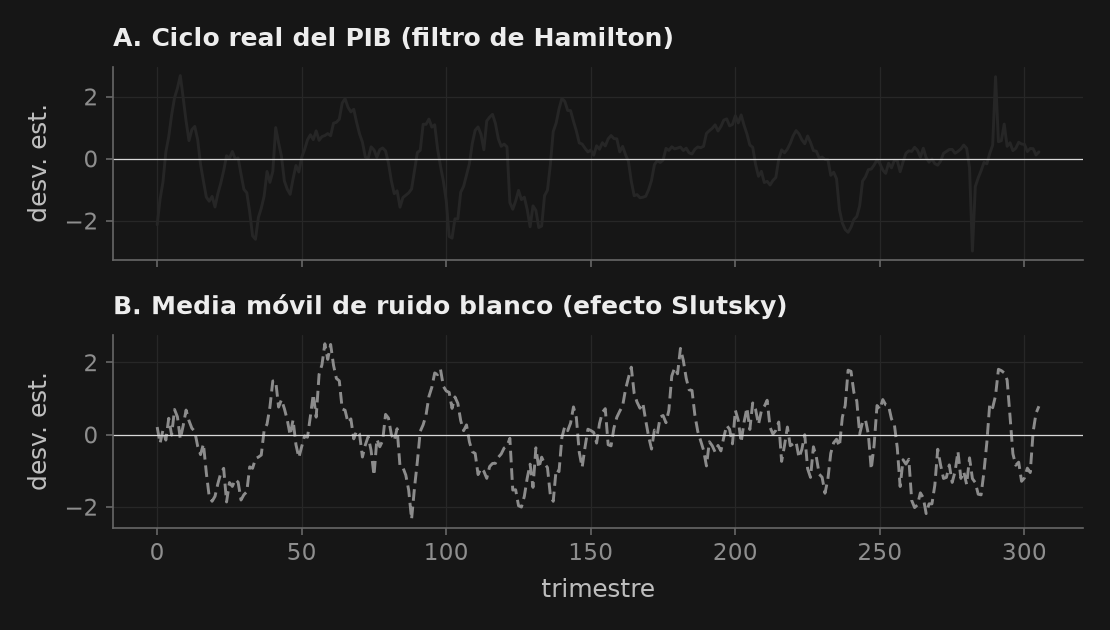

In [5]:
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(7.4, 4.2), sharex=True)
ax0.plot(cyc_y_norm, color="0.15", lw=1.4)
ax0.axhline(0, color="0.85", lw=0.6)
ax0.set_ylabel("desv. est.")
ax0.set_title("A. Ciclo real del PIB (filtro de Hamilton)")
ax1.plot(ma, color="0.55", lw=1.4, ls=(0, (4, 2)))
ax1.axhline(0, color="0.85", lw=0.6)
ax1.set_ylabel("desv. est."); ax1.set_xlabel("trimestre")
ax1.set_title("B. Media móvil de ruido blanco (efecto Slutsky)")
plt.tight_layout()
plt.show()

## 3. El reto mexicano: no es el signo, es la magnitud

Aquí hay una frase de libro de texto que conviene desarmar antes de repetirla: *"en las
emergentes el consumo es más volátil que el producto, $\sigma_c/\sigma_y>1$"*. Para México
**es falsa** con la convención de medición canónica del curso. Vamos a medirlo, no a
creerlo.

### La ficha de medición (sin ella el número no es replicable)

| decisión | convención del curso |
|---|---|
| **fuente y edición** | OCDE QNA vía SDMX, en el caché congelado `data/oecd_qna_apertura.csv` que viaja con las lecciones (la celda imprime su última observación) |
| serie de consumo | **hogares e ISFLSH** (P3, S1M), volúmenes |
| serie de producto | PIB (B1GQ, S1), volúmenes |
| **base de precios** | **base FIJA** (`PRICE_BASE=Q`, precios constantes) para México —el único así entre los países del caché—; los demás, volúmenes **encadenados** (`L`) |
| transformación | $100\log$ |
| **muestra** | **1995Q1–2019Q4** |
| orden de las operaciones | **recortar a la ventana y luego filtrar** |
| filtro | HP $\lambda=1600$ (principal) y Hamilton $(8,4)$ (robustez) |

Muevan un solo campo y el cociente mexicano llega hasta $1.050$ —ahí sí cruza el 1—; la
celda lo muestra campo por campo. Que el *signo* del "hecho estilizado" dependa de la
ficha es el ejercicio, no un accidente.

Sobre la base de precios: el campo está **declarado**, no contestado. Según los
metadatos de la OCDE que acompañan al panel del curso
(`curso/notebooks/data_curso/oecd_qna_panel_meta.csv`), el año de referencia de México
es 2018. Esta lección no prueba si un encadenado cambiaría el cociente; declararlo es
obligatorio (es uno de los campos de la ficha) y evita comparar peras con manzanas contra
los demás países.

In [6]:
crudo = pd.read_csv(DATA / "oecd_qna_apertura.csv", parse_dates=["date"])

# La base de precios es un campo de la ficha: se COMPRUEBA, no se afirma de palabra.
bases = crudo.groupby("code")["price_base"].apply(lambda s: set(s.unique()) - {"V"})
print("base de precios por país en el caché:", {c: sorted(b) for c, b in bases.items()})
print(f"países en el caché: {bases.size}; última observación: {pd.Period(crudo['date'].max(), 'Q')}")
assert bases["MEX"] == {"Q"}                                   # México, base FIJA
assert all(b == {"L"} for c, b in bases.items() if c != "MEX")  # los demás, encadenados

qna = crudo.pivot_table(index=["code", "date"], columns="variable", values="value")

INI_C, FIN_C = "1995-01-01", "2019-10-01"     # ventana CANÓNICA del curso


def momentos_ciclo(code, filtro="hp", ini=INI_C, fin=FIN_C, recortar_antes=True):
    """(n, sigma_y, sigma_c/sigma_y, corr(c,y)) del ciclo; cada argumento es un campo de la ficha."""
    d = qna.loc[code].sort_index().dropna(subset=["gdp_vol", "conh_vol"])
    if recortar_antes:                          # canónico: RECORTAR a la ventana y luego FILTRAR
        d = d[(d.index >= ini) & (d.index <= fin)]
    ly = 100 * np.log(d["gdp_vol"].to_numpy())
    lc = 100 * np.log(d["conh_vol"].to_numpy())
    filtra = (lambda x: hp_filter(x)[0]) if filtro == "hp" else (lambda x: hamilton_filter(x)[0])
    cy, cc = np.asarray(filtra(ly)), np.asarray(filtra(lc))
    ok = ~np.isnan(cy) & ~np.isnan(cc)          # Hamilton pierde sus primeras h+p-1 obs
    if not recortar_antes:                      # alternativa: filtrar todo y luego recortar
        ok &= (d.index >= ini) & (d.index <= fin)
    cy, cc = cy[ok], cc[ok]
    return int(ok.sum()), cy.std(), cc.std() / cy.std(), np.corrcoef(cc, cy)[0, 1]


print("\nsigma_c/sigma_y, OCDE QNA, hogares vs PIB, volúmenes, 1995Q1-2019Q4")
print("(base FIJA 'Q' para MEX; encadenada 'L' para USA; recorte ANTES de filtrar)\n")
print(f"{'país':<8}{'HP(1600)':>10}{'Hamilton(8,4)':>15}{'sigma_y HP (%)':>16}")
dato, dato_ham, sy_dato = {}, {}, {}
for code in ["MEX", "USA"]:
    n_dato, sy_dato[code], dato[code], _ = momentos_ciclo(code, "hp")
    _, _, dato_ham[code], _ = momentos_ciclo(code, "hamilton")
    print(f"{code:<8}{dato[code]:>10.3f}{dato_ham[code]:>15.3f}{sy_dato[code]:>16.2f}")

# Moverle UN solo campo a la ficha, dejando los demás en su valor canónico.
fichas = {
    "canónica (HP, recortar y luego filtrar)": {},
    "filtro de Hamilton(8,4)": dict(filtro="hamilton"),
    "filtrar y luego recortar": dict(recortar_antes=False),
    "muestra desde 1994Q1 (inicio del caché)": dict(ini="1994-01-01"),
    "muestra hasta el final del caché": dict(fin="2026-12-31"),
}
print("\nMéxico: sigma_c/sigma_y moviendo UN solo campo de la ficha")
sens = {}
for nombre, kw in fichas.items():
    n_f, _, sens[nombre], _ = momentos_ciclo("MEX", **kw)
    print(f"  {nombre:<42}{sens[nombre]:>7.3f}   (n = {n_f})")
print(f"  rango: {min(sens.values()):.3f} a {max(sens.values()):.3f}")

# La misma ficha para todos los países del caché.
seccion = pd.DataFrame([momentos_ciclo(c) for c in bases.index], index=bases.index,
                       columns=["n", "sigma_y", "sc_sy", "corr_cy"]).sort_values("sc_sy")
lugar_mex = int(np.flatnonzero(seccion.index == "MEX")[0]) + 1
lugar_corr = int((seccion["corr_cy"] > seccion.loc["MEX", "corr_cy"]).sum()) + 1
print(f"\nsección cruzada, ficha canónica (ordenada por sigma_c/sigma_y):")
print(seccion.round({"sigma_y": 2, "sc_sy": 3, "corr_cy": 2}).to_string())
print(f"México: lugar {lugar_mex} de {len(seccion)} en sigma_c/sigma_y (de menor a mayor); "
      f"mediana {seccion['sc_sy'].median():.3f}")
print(f"México: lugar {lugar_corr} de {len(seccion)} en corr(c,y) (de mayor a menor); "
      f"mediana {seccion['corr_cy'].median():.2f}")

# EL HECHO, enunciado como toca: el consumo mexicano NO es más volátil que el producto con
# esta convención; lo que sorprende es lo cerca que está del 1.
assert dato["MEX"] < 1.0 and dato["MEX"] > dato["USA"]
# Guardia de datos: la prosa cita estos valores; si el caché cambia, hay que releerla.
assert abs(dato["MEX"] - 0.959) < 0.01 and abs(dato["USA"] - 0.795) < 0.01
# La desigualdad es frágil: basta mover UN campo para cruzar el 1.
assert max(sens.values()) > 1.0

base de precios por país en el caché: {'AUS': ['L'], 'CAN': ['L'], 'CHL': ['L'], 'COL': ['L'], 'DEU': ['L'], 'MEX': ['Q'], 'TUR': ['L'], 'USA': ['L']}
países en el caché: 8; última observación: 2026Q2

sigma_c/sigma_y, OCDE QNA, hogares vs PIB, volúmenes, 1995Q1-2019Q4
(base FIJA 'Q' para MEX; encadenada 'L' para USA; recorte ANTES de filtrar)

país      HP(1600)  Hamilton(8,4)  sigma_y HP (%)
MEX          0.959          0.968            1.90
USA          0.795          0.852            1.03

México: sigma_c/sigma_y moviendo UN solo campo de la ficha
  canónica (HP, recortar y luego filtrar)     0.959   (n = 100)
  filtro de Hamilton(8,4)                     0.968   (n = 89)


  filtrar y luego recortar                    0.972   (n = 100)
  muestra desde 1994Q1 (inicio del caché)     0.998   (n = 104)
  muestra hasta el final del caché            1.050   (n = 125)
  rango: 0.959 a 1.050



sección cruzada, ficha canónica (ordenada por sigma_c/sigma_y):
        n  sigma_y  sc_sy  corr_cy
code                              
DEU   100     1.44  0.407     0.47
CAN   100     1.05  0.640     0.61
USA   100     1.03  0.795     0.87
COL    60     1.27  0.833     0.82
MEX   100     1.90  0.959     0.85
TUR    96     3.33  1.063     0.85
CHL    96     1.75  1.314     0.90
AUS   100     0.55  1.414     0.59
México: lugar 5 de 8 en sigma_c/sigma_y (de menor a mayor); mediana 0.896
México: lugar 3 de 8 en corr(c,y) (de mayor a menor); mediana 0.83


### El modelo, medido con la **misma** ficha

Un dato de $100\log$ filtrado con HP sólo se compara con el **mismo objeto** del
modelo. Escribimos el RBC cerrado canónico (calibración trimestral estándar del mazo A4:
$\alpha=0.33$, $\beta=0.99$, $\delta=0.025$, $\nu=1.5$, $\rho_a=0.95$, $\sigma_a=0.007$,
horas de estado estacionario $1/3$; **ningún parámetro sale de datos mexicanos**) con
cada variable en **logaritmos**, y pedimos sus momentos teóricos con
`theoretical_moments(hp_filter=1600)`: el filtro HP de dos colas aplicado en el dominio
de la frecuencia a la solución de primer orden.

Tres comprobaciones, cada una con su etiqueta:

1. **Oráculo independiente: Dynare.** El mismo modelo, escrito como `.mod` y resuelto con
   Dynare 8 (`8-unstable-2026-05-26-1801-f6a469d4`, MATLAB R2026a, corrido el
   30-sep-2026 con `stoch_simul(order=1, irf=0, ar=1, nograph, hp_filter=1600)`).
   Dynare tiene su propio preprocesador, sus propias derivadas, su propio solver de
   estado estacionario y su propio cálculo espectral del HP. Sus desviaciones estándar,
   correlación y autocorrelación quedan **congeladas** en la celda; el `.mod` está al
   final de esta sección para que lo corras tú.
2. **Chequeo interno: el filtro por otro camino.** Una simulación de $10^5$ trimestres
   filtrada en el **dominio del tiempo**. Usa las mismas reglas de decisión de
   `puremacro`, así que sólo verifica el cálculo espectral del filtro, no el modelo.
3. **Muestras del tamaño del dato.** El cociente de los datos sale de una ventana
   finita; simulamos muchas ventanas de la misma longitud, les aplicamos la **misma**
   función `hp_filter` y vemos cuánto se mueve el cociente del modelo por puro azar
   muestral.

In [7]:
from puremacro.dsge import build_dynare

# RBC cerrado canónico: calibración trimestral estándar (mazo A4), NO calibrado a México.
_alpha, _beta, _delta, _nu = 0.33, 0.99, 0.025, 1.5
_rho_a, _sigma_a = 0.95, 0.007
_l_ss = 0.33
_r_ss = 1.0 / _beta - 1.0 + _delta                      # Euler en estado estacionario
_ky = _alpha / _r_ss
_y_ss = (_ky ** (_alpha / (1.0 - _alpha))) * _l_ss
_k_ss = _ky * _y_ss
_i_ss = _delta * _k_ss
_c_ss = _y_ss - _i_ss
_w_ss = (1.0 - _alpha) * _y_ss / _l_ss
_mu = _w_ss / (_c_ss * ((1.0 - _l_ss) ** (-_nu)))       # peso del ocio que da l_ss = 1/3

VARS = ["y", "c", "i", "k", "l", "r", "w", "a"]
SS_LOG = {"y": np.log(_y_ss), "c": np.log(_c_ss), "i": np.log(_i_ss), "k": np.log(_k_ss),
          "l": np.log(_l_ss), "r": np.log(_r_ss), "w": np.log(_w_ss), "a": 0.0}
X = np.exp


def _rbc_log(lead, curr, lag, e, p):
    # Cada variable salvo a (que ya es log-PTF) es el LOGARITMO de su nivel: los momentos
    # del modelo salen en log, igual que los datos. X(v) = exp(v) es el nivel.
    return [
        1.0 / X(curr.c) - p.beta / X(lead.c) * (1.0 + X(lead.r) - p.delta),     # Euler
        p.mu * (1.0 - X(curr.l)) ** (-p.nu) - X(curr.w) / X(curr.c),          # consumo-ocio
        X(curr.y) - X(curr.a) * X(lag.k) ** p.alpha * X(curr.l) ** (1.0 - p.alpha),
        X(curr.k) - (1.0 - p.delta) * X(lag.k) - X(curr.i),                   # acumulación
        X(curr.y) - X(curr.c) - X(curr.i),                                    # recursos
        X(curr.r) - p.alpha * X(curr.y) / X(lag.k),                           # renta del capital
        X(curr.w) - (1.0 - p.alpha) * X(curr.y) / X(curr.l),                  # salario
        curr.a - p.rho_a * lag.a - e.eps_a,                                   # PTF AR(1)
    ]


def modelo_rbc(rho_a=_rho_a, sigma_a=_sigma_a):
    params = {"alpha": _alpha, "beta": _beta, "delta": _delta, "nu": _nu, "mu": _mu, "rho_a": rho_a}
    return build_dynare(_rbc_log, variables=VARS, shocks=["eps_a"], params=params,
                        steady_state=SS_LOG, shock_cov=np.array([[sigma_a ** 2]]))


mod_rbc = modelo_rbc()
# Chequeos INTERNOS (no validan nada fuera de puremacro): residuos del EE y Blanchard-Kahn.
assert mod_rbc.resid().abs().max() < 1e-10, "residuos de estado estacionario"
assert mod_rbc.check().is_determinate, "condición de Blanchard-Kahn"

tm_hp = mod_rbc.theoretical_moments(hp_filter=1600)    # HP de dos colas, en frecuencia
tm_crudo = mod_rbc.theoretical_moments()               # sin filtrar
sd_hp, sd_crudo = tm_hp.moments["Std.Dev."], tm_crudo.moments["Std.Dev."]
RBC_CERRADO = float(sd_hp["c"] / sd_hp["y"])           # sigma_c/sigma_y con la ficha de los datos
rbc_crudo = float(sd_crudo["c"] / sd_crudo["y"])
rbc_sy_hp = float(100 * sd_hp["y"])                    # sigma_y del modelo, en %
cy_ss = _c_ss / _y_ss                                  # a primer orden: niveles = logs x c/y

print("El MISMO modelo medido de cuatro maneras: sigma_c/sigma_y")
print(f"  logs,    HP(1600)     {RBC_CERRADO:.3f}   <- la ficha de los datos")
print(f"  logs,    sin filtrar  {rbc_crudo:.3f}")
print(f"  niveles, HP(1600)     {RBC_CERRADO * cy_ss:.3f}")
print(f"  niveles, sin filtrar  {rbc_crudo * cy_ss:.3f}")
print(f"  (a primer orden sd(nivel) = nivel de EE x sd(log), así que niveles = logs x c/y = logs x {cy_ss:.3f})")

# Oráculo INDEPENDIENTE, congelado: Dynare 8-unstable-2026-05-26-1801-f6a469d4 + MATLAB R2026a,
# 30-sep-2026, sobre el .mod del final de esta sección. Valores: sqrt(diag(oo_.var)),
# correlación de oo_.var y oo_.autocorr{1}, con hp_filter=1600 (HP) y sin filtro (crudo).
DYNARE = {
    "HP":    {"sd_y": 0.012598684992277204, "sd_c": 0.004202289077042135,
              "sd_i": 0.04163037936838973, "sd_l": 0.0051611392445735284,
              "corr_cy": 0.905208474692816, "ac1_y": 0.7189209431515606},
    "crudo": {"sd_y": 0.0361375767854971, "sd_c": 0.027032464471359572},
}
nuestro = {
    "HP":    {"sd_y": sd_hp["y"], "sd_c": sd_hp["c"], "sd_i": sd_hp["i"], "sd_l": sd_hp["l"],
              "corr_cy": tm_hp.correlation.loc["c", "y"], "ac1_y": tm_hp.autocorr.loc["y", "Lag 1"]},
    "crudo": {"sd_y": sd_crudo["y"], "sd_c": sd_crudo["c"]},
}
desv_dynare = max(abs(nuestro[f][m] / DYNARE[f][m] - 1) for f in DYNARE for m in DYNARE[f])
r_dynare = DYNARE["HP"]["sd_c"] / DYNARE["HP"]["sd_y"]
print(f"\nDynare 8 (congelado) vs puremacro: sigma_c/sigma_y con HP = {r_dynare:.4f} vs {RBC_CERRADO:.4f}")
print(f"  máx. desviación relativa en las {sum(len(v) for v in DYNARE.values())} cifras comparadas: "
      f"{desv_dynare:.0e}")
assert desv_dynare < 1e-8, "puremacro se separa de Dynare"

El MISMO modelo medido de cuatro maneras: sigma_c/sigma_y
  logs,    HP(1600)     0.334   <- la ficha de los datos
  logs,    sin filtrar  0.748
  niveles, HP(1600)     0.255
  niveles, sin filtrar  0.572
  (a primer orden sd(nivel) = nivel de EE x sd(log), así que niveles = logs x c/y = logs x 0.765)

Dynare 8 (congelado) vs puremacro: sigma_c/sigma_y con HP = 0.3335 vs 0.3335
  máx. desviación relativa en las 8 cifras comparadas: 5e-13


In [8]:
from scipy.linalg import solve_banded


def hp_ciclo_largo(x, lam=1600.0):
    """Ciclo HP de una serie LARGA: el mismo sistema (I + lam K'K) tau = x que resuelve
    puremacro.data.hp_filter, pero guardado como matriz pentadiagonal (la versión densa
    de 10^5 x 10^5 no cabe en memoria)."""
    n = len(x)
    d0 = np.full(n, 1 + 6 * lam); d0[[0, -1]] = 1 + lam; d0[[1, -2]] = 1 + 5 * lam
    d1 = np.full(n - 1, -4 * lam); d1[[0, -1]] = -2 * lam
    ab = np.zeros((5, n))
    ab[0, 2:] = lam; ab[1, 1:] = d1; ab[2] = d0; ab[3, :-1] = d1; ab[4, :-2] = lam
    return x - solve_banded((2, 2), ab, x)


x_prueba = np.random.default_rng(0).standard_normal(300).cumsum()
assert np.max(np.abs(hp_ciclo_largo(x_prueba) - np.asarray(hp_filter(x_prueba)[0]))) < 1e-8

# (2) Una simulación LARGA, filtrada en el tiempo; recortamos los bordes, donde el HP es de una cola.
T_LARGO, BORDE = 100_000, 200
sim = mod_rbc.simulate(periods=T_LARGO, seed=2026, burn=500)
cy_l = hp_ciclo_largo(100 * sim["y"].to_numpy())[BORDE:-BORDE]
cc_l = hp_ciclo_largo(100 * sim["c"].to_numpy())[BORDE:-BORDE]
r_largo = cc_l.std() / cy_l.std()
print(f"simulación de {T_LARGO:,} trimestres, HP en el tiempo: sigma_c/sigma_y = {r_largo:.3f} "
      f"(teórico {RBC_CERRADO:.3f}; diferencia relativa {r_largo / RBC_CERRADO - 1:+.1%})")
assert abs(r_largo / RBC_CERRADO - 1) < 0.015   # error de Monte Carlo ~0.15% con T = 10^5

# (3) Muestras de la MISMA longitud que la ventana de datos, con la MISMA función hp_filter.
#     Bloques consecutivos de una simulación: cada uno arranca en la distribución estacionaria.
R = 1000
sim_m = mod_rbc.simulate(periods=R * n_dato, seed=7, burn=500)
Ym = 100 * sim_m["y"].to_numpy().reshape(R, n_dato)
Cm = 100 * sim_m["c"].to_numpy().reshape(R, n_dato)
r_muestras = np.array([np.asarray(hp_filter(c)[0]).std() / np.asarray(hp_filter(yy)[0]).std()
                       for yy, c in zip(Ym, Cm)])
p5, p50, p95 = np.percentile(r_muestras, [5, 50, 95])
print(f"{R} muestras de {n_dato} trimestres: mediana {p50:.2f}, 5-95%: {p5:.2f}-{p95:.2f}, "
      f"máximo {r_muestras.max():.2f}")
print(f"  ficha mexicana más baja de la tabla de arriba: {min(sens.values()):.3f}")

print(f"\n{'':<24}{'HP(1600)':>10}{'sigma_y HP (%)':>16}")
print(f"{'MEX (dato)':<24}{dato['MEX']:>10.3f}{sy_dato['MEX']:>16.2f}")
print(f"{'USA (dato)':<24}{dato['USA']:>10.3f}{sy_dato['USA']:>16.2f}")
print(f"{'RBC cerrado (teórico)':<24}{RBC_CERRADO:>10.3f}{rbc_sy_hp:>16.2f}")
brecha = dato["MEX"] - RBC_CERRADO
print(f"\nbrecha modelo cerrado vs México = {brecha:.2f} ({dato['MEX'] / RBC_CERRADO:.1f} veces)")

# Ninguna muestra del modelo llega a ninguna de las fichas mexicanas: la brecha no es azar muestral.
assert r_muestras.max() < min(sens.values())
assert dato["MEX"] > dato["USA"] > RBC_CERRADO

simulación de 100,000 trimestres, HP en el tiempo: sigma_c/sigma_y = 0.334 (teórico 0.334; diferencia relativa +0.2%)


1000 muestras de 100 trimestres: mediana 0.33, 5-95%: 0.31-0.36, máximo 0.41
  ficha mexicana más baja de la tabla de arriba: 0.959

                          HP(1600)  sigma_y HP (%)
MEX (dato)                   0.959            1.90
USA (dato)                   0.795            1.03
RBC cerrado (teórico)        0.334            1.26

brecha modelo cerrado vs México = 0.63 (2.9 veces)


**El `.mod` del oráculo** (córrelo con Dynare ≥ 6 para reproducir las cifras congeladas;
`mu` es el valor que imprime `_mu` con todos sus dígitos):

```
var y c k l i w r a;
varexo e_a;
parameters alpha beta delta mu nu rho_a;
alpha = 0.33; beta = 0.99; delta = 0.025; mu = 1.455566505196236; nu = 1.5; rho_a = 0.95;
model;  // todas las variables salvo a son LOGARITMOS
mu * (1 - exp(l))^(-nu) * exp(c) = exp(w);
exp(c(+1))/(beta*exp(c)) = exp(r(+1)) + 1 - delta;
exp(r) = alpha * exp(y) / exp(k(-1));
exp(w) = (1 - alpha) * exp(y) / exp(l);
exp(y) = exp(a) * exp(k(-1))^alpha * exp(l)^(1-alpha);
exp(y) = exp(c) + exp(i);
exp(k) = (1 - delta)*exp(k(-1)) + exp(i);
a = rho_a * a(-1) + e_a;
end;
initval; y = -0.005; c = -0.27; i = -1.45; k = 2.24; l = -1.11; w = 0.70; r = -3.35; a = 0; end;
steady; check;
shocks; var e_a; stderr 0.007; end;
stoch_simul(order=1, irf=0, ar=1, nograph, hp_filter=1600);
```

Quita `hp_filter=1600` para la fila "crudo". Dynare encuentra el estado estacionario por
su cuenta a partir de esos `initval` redondeados.

### Lo que dicen los números
México: $\sigma_c/\sigma_y=0.959$ con HP y $0.968$ con Hamilton. EE. UU., con la **misma**
serie y la **misma** ventana: $0.795$ y $0.852$. El RBC cerrado canónico, medido con la
**misma** ficha (logaritmos, HP de $\lambda=1600$), entrega $0.334$. Dynare, por su
cuenta, da lo mismo: $0.3335$ contra $0.3335$. La simulación larga filtrada en el tiempo
da $0.334$. Y en $1000$ ventanas de $100$ trimestres el cociente del modelo tiene
mediana $0.33$, se mueve entre $0.30$ y $0.36$ (5–95 %) y nunca pasa de $0.41$. Entonces:

- El fallo del modelo **no es de signo**: el modelo predice $<1$ y el dato es $<1$. Los dos
  están del mismo lado del 1.
- El fallo es de **magnitud, y es enorme**: el cociente mexicano es $2.9$ veces el del
  modelo, una brecha de $0.63$. No es azar muestral: ninguna ventana simulada llega
  siquiera a la ficha mexicana más baja.
- El contraste con EE. UU. sobrevive intacto ($0.959$ contra $0.795$): México suaviza menos.
  Eso es lo que hay que explicar, y no necesita ningún $>1$.

**La ficha también es del modelo.** El mismo modelo da $0.748$ sin filtrar y $0.572$ si
además se mide en niveles: el filtro quita las frecuencias bajas, donde consumo y
producto se mueven juntos, y medir en niveles multiplica el cociente por $c/y=0.765$.
Comparar cualquiera de esas cifras con el $0.959$ mexicano sería mezclar fichas. El
$\sigma_y$ del modelo, $1.26\%$, queda además por debajo del mexicano ($1.90\%$).

Dos advertencias de honestidad, porque el curso las va a cobrar:

1. **En sección cruzada México no es un caso extremo.** Con esta misma ficha, en los $8$
   países del caché la mediana de $\sigma_c/\sigma_y$ es $0.896$ y México ocupa el
   **lugar 5 de 8** de menor a mayor. El cociente por sí solo no separa emergentes de
   avanzadas: Chile ($1.314$) y Turquía ($1.063$) pasan del 1, pero Australia ($1.414$)
   también, y Colombia ($0.833$) queda por debajo de México. Ojo: Colombia sólo tiene
   $60$ trimestres en la ventana, y Chile y Turquía $96$.
2. **El comovimiento es alto, pero tampoco es récord.** $\mathrm{corr}(c,y)$ cíclica con
   HP: Chile $0.90$, EE. UU. $0.87$, México $0.85$ — México es el **lugar 3 de 8**, con
   mediana $0.83$. Alto, sí; excepcional, no.

Moraleja metodológica: un hecho estilizado enunciado como desigualdad (*"$>1$"*) es frágil
—lo decide la ficha de medición—; enunciado como magnitud (*"$0.959$ contra $0.334$ del
modelo"*) es robusto y además dice cuánto tiene que trabajar la teoría.

### El mecanismo candidato: "the cycle is the trend"
¿De dónde puede salir un cociente tan alto? Aguiar y Gopinath (2007) proponen que en las
emergentes los choques golpean la **tasa de crecimiento tendencial**, no sólo el nivel. Si
el choque es casi permanente, el ingreso futuro esperado sube tanto como el actual y el
hogar **no tiene motivo para suavizar**: el consumo sigue al producto de cerca, o incluso
lo rebasa.

Lo ilustramos con una simulación de renta permanente (datos **SIMULADOS**, declarados).
Ojo con la lectura: las economías simuladas son **regímenes de choques**, no retratos de
países, y esto **no** es el RBC: es una regla de consumo escrita a mano, no la solución de
un problema de optimización. Lo único que autoriza el ejercicio es la **estática
comparativa** —qué le pasa al cociente cuando sube el peso del choque de tendencia—, no el
nivel de ninguna de las barras. Ajustar el nivel a la cifra mexicana es trabajo del mazo de
economía abierta.

In [9]:
def economia(sig_g, sig_z, *, rho_g=0.8, theta=0.35, seed=0, T=400):
    """Renta permanente à la Aguiar-Gopinath (2007), SIMULADA.

    - g_t: choque persistente a la TASA de crecimiento (AR(1)), acumulado en la tendencia.
    - z_t: choque transitorio al NIVEL del producto.
    El consumo sigue el componente permanente y anticipa el crecimiento futuro (kappa*g_t),
    por lo que sobre-reacciona cuando dominan los choques a la tendencia.

    OJO, esto NO es el RBC resuelto: es una regla de consumo POSTULADA. En particular
    `theta` es la fracción del choque transitorio que se consume, un PARÁMETRO LIBRE, no un
    resultado. Con sig_g=0 se tiene log_con = theta*log_out término a término y, como el HP
    es lineal, el cociente sale EXACTAMENTE theta. Lo informativo aquí es cómo se mueve el
    cociente al variar sig_g, no su nivel.
    """
    r = np.random.default_rng(seed)
    g = np.zeros(T)
    for t in range(1, T):
        g[t] = rho_g * g[t - 1] + r.normal(0.0, sig_g)   # choque persistente al crecimiento
    X = np.cumsum(g)                                      # tendencia estocástica (log-nivel)
    z = r.normal(0.0, sig_z, T)                           # choque transitorio al nivel
    log_out = X + z
    kappa = rho_g / (1.0 - rho_g)                         # valor presente del crecimiento
    log_con = X + kappa * g + theta * z                  # consumo de renta permanente
    cy, _ = hp_filter(log_out); cc, _ = hp_filter(log_con)
    cy, cc = np.asarray(cy), np.asarray(cc)
    return cc.std() / cy.std(), np.corrcoef(cy, cc)[0, 1]

THETA = 0.35
rel_pu, corr_pu = economia(sig_g=0.0, sig_z=1.0, theta=THETA, seed=101)    # transitorio puro
rel_tr, corr_tr = economia(sig_g=0.15, sig_z=1.0, theta=THETA, seed=101)   # mezcla
rel_te, corr_te = economia(sig_g=1.0, sig_z=0.4, theta=THETA, seed=202)    # tendencia domina

print(f"transitorio PURO (sig_g=0):   sigma_c/sigma_y = {rel_pu:.2f}   corr(c,y) = {corr_pu:.2f}")
print(f"mezcla (sig_g=0.15):          sigma_c/sigma_y = {rel_tr:.2f}   corr(c,y) = {corr_tr:.2f}")
print(f"tendencia domina (sig_g=1):   sigma_c/sigma_y = {rel_te:.2f}   corr(c,y) = {corr_te:.2f}")
print(f"\ndato México (HP, ventana canónica) = {dato['MEX']:.2f}   corr(c,y) = "
      f"{seccion.loc['MEX', 'corr_cy']:.2f}   |   RBC cerrado (logs, HP) = {RBC_CERRADO:.2f}")

# Comprobación de que el 0.35 es theta y no un hallazgo: con sig_g=0 el cociente ES theta.
assert abs(rel_pu - THETA) < 1e-10 and abs(corr_pu - 1.0) < 1e-10
assert rel_pu < rel_tr < rel_te        # LO QUE SÍ dice el ejercicio: la tendencia sube el
                                       # cociente, y mucho (estática comparativa)
assert corr_tr < corr_pu and corr_te < corr_pu   # ...y a costa de bajar el comovimiento
assert rel_tr < dato["MEX"] < rel_te   # el dato mexicano queda ENTRE la mezcla y la tendencia

transitorio PURO (sig_g=0):   sigma_c/sigma_y = 0.35   corr(c,y) = 1.00
mezcla (sig_g=0.15):          sigma_c/sigma_y = 0.91   corr(c,y) = 0.61
tendencia domina (sig_g=1):   sigma_c/sigma_y = 1.75   corr(c,y) = 0.69

dato México (HP, ventana canónica) = 0.96   corr(c,y) = 0.85   |   RBC cerrado (logs, HP) = 0.33


### La escala del problema, en una figura
Las cinco barras están en la misma escala y ordenan el argumento entero. **Léanlas como
pendientes, no como niveles.** Sin choques a la tendencia el cociente simulado es $0.35$,
que es *exactamente* el $\theta$ que le pusimos a la regla de consumo: con $\sigma_g=0$ el
consumo es $\theta$ veces el producto en cada periodo y el filtro HP es lineal, así que ese
$0.35$ es un **supuesto**, no un resultado — está ahí sólo para fijar la escala del caso
transitorio. Que caiga cerca del RBC ($0.33$) es una coincidencia de calibración y **no
valida** al modelo; el $0.33$ del RBC sí sale de resolverlo, y el bigote sobre su barra
es el rango 5–95 % en ventanas de $100$ trimestres. Lo que sí es un resultado: basta un
componente **pequeño** de tendencia ($\sigma_g=0.15$ contra $\sigma_z=1$) para subir a
$0.91$, y con la tendencia dominando el cociente se dispara a $1.75$, muy por encima de
México — el mismo $\theta$ en los tres casos.

Nótese dónde queda la línea del $1$: el dato mexicano **no la cruza**, y aun así la
distancia al modelo cerrado es de $0.63$. El reto es esa distancia, no la línea.

Y una honestidad más, que la salida imprime y conviene no saltarse: el canal de la
tendencia sube el cociente pero **baja el comovimiento**, de $1.00$ en el caso transitorio
puro a $0.61$ y $0.69$, mientras México tiene $\mathrm{corr}(c,y)=0.85$. Es decir, el canal
empuja el momento que nos interesa en la dirección correcta y otro momento en la dirección
equivocada. Cerrar los dos a la vez es justo lo que exige el modelo de economía abierta.

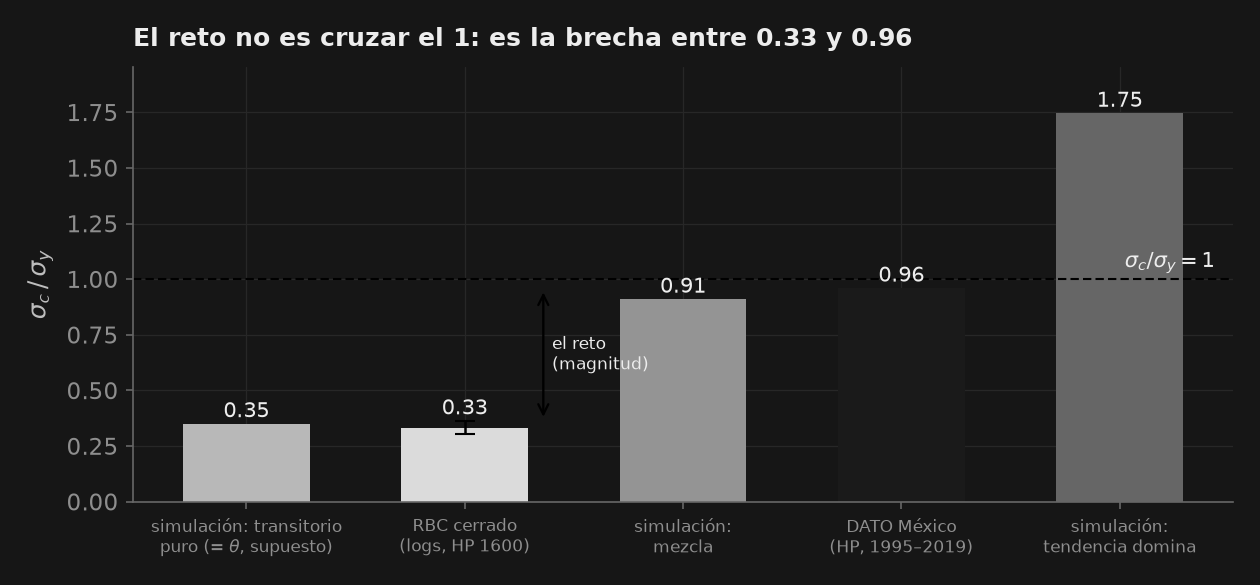

In [10]:
fig, ax = plt.subplots(figsize=(8.4, 3.9))
labels = [r"simulación: transitorio" "\n" r"puro (= $\theta$, supuesto)", "RBC cerrado\n(logs, HP 1600)",
          "simulación:\nmezcla", "DATO México\n(HP, 1995–2019)",
          "simulación:\ntendencia domina"]
vals = [rel_pu, RBC_CERRADO, rel_tr, dato["MEX"], rel_te]
colores = ["0.72", "0.86", "0.58", "0.10", "0.40"]
bars = ax.bar(labels, vals, color=colores, width=0.58)
# Bigote: rango 5-95% del cociente del modelo en ventanas de n_dato trimestres.
ax.errorbar(1, RBC_CERRADO, yerr=[[RBC_CERRADO - p5], [p95 - RBC_CERRADO]],
            color="0.0", lw=1.2, capsize=5)
ax.axhline(1.0, color="0.0", lw=1.0, ls=(0, (4, 2)))
ax.text(4.44, 1.02, r"$\sigma_c/\sigma_y=1$", va="bottom", ha="right", fontsize=10)
ax.annotate("", xy=(1.36, p95), xytext=(1.36, dato["MEX"]),
            arrowprops=dict(arrowstyle="<->", color="0.0", lw=1.1))
ax.text(1.40, (p95 + dato["MEX"]) / 2, "el reto\n(magnitud)", fontsize=8, va="center")
for i_b, (b, v) in enumerate(zip(bars, vals)):
    tope = max(v, p95) if i_b == 1 else v             # la etiqueta del RBC va sobre el bigote
    ax.text(b.get_x() + b.get_width() / 2, tope + 0.03, f"{v:.2f}", ha="center", fontsize=10)
ax.tick_params(axis="x", labelsize=8)
ax.set_ylabel(r"$\sigma_c\,/\,\sigma_y$")
ax.set_ylim(0, max(vals) * 1.12)
ax.set_title(f"El reto no es cruzar el 1: es la brecha entre {RBC_CERRADO:.2f} y {dato['MEX']:.2f}")
plt.tight_layout()
plt.show()

### Las tres salidas del reto
Para que un RBC cierre la brecha de magnitud —del $0.334$ del modelo hasta el $0.959$
mexicano— la literatura ofrece tres puertas (no excluyentes):
1. **La productividad: choques más grandes ($\sigma_a$) o más persistentes ($\rho_a$).**
   Si el choque dura más, la **renta del capital** y el ingreso permanente se mueven más y
   el consumo con ellos. Son dos perillas distintas, y la celda *Tu turno* las separa.
2. **La tendencia.** Choques a la *tasa de crecimiento* tendencial (Aguiar–Gopinath): el
   ingreso futuro esperado sube y el consumo sobre-reacciona hoy. Es la salida que
   simulamos arriba.
3. **La tasa de interés país ($q_t$).** Un *spread* soberano contracíclico (sube en
   recesión) más fricciones financieras y **tipo de cambio** amplifican los choques y
   desincronizan consumo y producto — canal central en la macro de economías abiertas
   emergentes.

### Tu turno: la salida 1, medida con la misma ficha
La celda de abajo vuelve a resolver el RBC en logaritmos con otro $\sigma_a$ o con otro
$\rho_a$ (lo demás, igual) y lo mide con HP(1600). Rango anunciado:
$\rho_a\in[0.50,\ 0.995]$ y $\sigma_a\in[0.001,\ 0.05]$. **Predice antes de correr.**
1. *(básico)* Duplica $\sigma_a$ (`sigma_nuevo = 0.014`). ¿Qué le pasa a
   $\sigma_c/\sigma_y$? ¿Y a $\sigma_y$?
2. *(intermedio)* Sube $\rho_a$ a $0.99$ y luego a $0.995$. ¿Sube o baja el cociente?
   ¿Qué fracción de la brecha con México cierra?
3. *(reto)* Con $\rho_a=0.995$ el cociente **sin filtrar** queda cerca del dato
   mexicano y el filtrado no. ¿Por qué? Pista: ¿en qué frecuencias vive el comovimiento
   que el HP quita? ¿Qué distingue un choque de nivel muy persistente de un choque a la
   **tasa de crecimiento** como el de la salida 2?

In [11]:
sigma_nuevo = 0.014   # ← cambia esto: desv. est. del choque de PTF, rango [0.001, 0.05]
rho_nuevo = 0.99      # ← cambia esto: persistencia de la PTF, rango [0.50, 0.995]


def cociente_rbc(rho_a, sigma_a, hp=1600.0):
    """(sigma_c/sigma_y, sigma_y en %) del RBC en logs; hp=None para no filtrar."""
    s = modelo_rbc(rho_a=rho_a, sigma_a=sigma_a).theoretical_moments(hp_filter=hp).moments["Std.Dev."]
    return float(s["c"] / s["y"]), float(100 * s["y"])


r_sig, sy_sig = cociente_rbc(_rho_a, sigma_nuevo)
r_rho, sy_rho = cociente_rbc(rho_nuevo, _sigma_a)
r_rho_crudo, _ = cociente_rbc(rho_nuevo, _sigma_a, hp=None)
cierra = (r_rho - RBC_CERRADO) / (dato["MEX"] - RBC_CERRADO)
print(f"base   (rho_a={_rho_a}, sigma_a={_sigma_a}):  sigma_c/sigma_y = {RBC_CERRADO:.3f}   sigma_y = {rbc_sy_hp:.2f}%")
print(f"sigma_a = {sigma_nuevo}:               sigma_c/sigma_y = {r_sig:.3f}   sigma_y = {sy_sig:.2f}%")
print(f"rho_a   = {rho_nuevo}:                sigma_c/sigma_y = {r_rho:.3f}   sigma_y = {sy_rho:.2f}%"
      f"   (sin filtrar: {r_rho_crudo:.3f})")
print(f"fracción de la brecha con México que cierra rho_a = {rho_nuevo}: {cierra:.0%}")

# 1. A primer orden y con un solo choque, sigma_a escala c e y en la MISMA proporción.
assert abs(r_sig - RBC_CERRADO) < 1e-8
# 2. Más persistencia -> el consumo sigue más al producto (y menos persistencia, al revés).
assert (r_rho - RBC_CERRADO) * (rho_nuevo - _rho_a) >= 0
# 3. ...pero en todo el rango anunciado la salida 1 sola no llega al dato mexicano.
assert r_rho < dato["MEX"]

base   (rho_a=0.95, sigma_a=0.007):  sigma_c/sigma_y = 0.334   sigma_y = 1.26%
sigma_a = 0.014:               sigma_c/sigma_y = 0.334   sigma_y = 2.52%
rho_a   = 0.99:                sigma_c/sigma_y = 0.492   sigma_y = 1.14%   (sin filtrar: 0.927)
fracción de la brecha con México que cierra rho_a = 0.99: 25%


## 4. Preguntas para pensar
1. En la parte 1, la persistencia del ciclo real del PIB ($0.89$) y la de la media móvil
   de ruido blanco de la parte 2 ($0.88$) son casi iguales. ¿Qué momento **adicional**
   propondrías para distinguir un ciclo con mecanismo económico de uno puramente
   estadístico (Slutsky)?
2. La renta permanente predice $\sigma_c/\sigma_y<1$ con choques transitorios pero puede
   dar $>1$ con choques a la tendencia. ¿Por qué el consumo **anticipa** el crecimiento
   futuro y salta por encima del producto? Explica el papel de $\kappa=\rho/(1-\rho)$.
3. **El hecho, bien enunciado.** El dato mexicano es $0.959$ y el modelo cerrado, con la
   misma ficha, $0.334$: ¿por qué es más informativo reportar esa brecha que la
   desigualdad "$\sigma_c/\sigma_y>1$"? Escribe las dos versiones del hecho estilizado y di,
   para cada una, qué tendría que ocurrir en los datos para **falsarla**. Pista: una
   depende de la ficha de medición y la otra no.
4. De las tres salidas (productividad, tendencia, $q_t$), ¿cuál te parece más plausible
   para México en la crisis de 1994–95 y por qué? Piensa en el **tipo de cambio** y la
   **tasa de interés país**. Ojo con la salida 1: subir $\sigma_a$ mueve numerador **y**
   denominador — ¿por qué eso la hace mala candidata para cerrar la brecha?

### Notas para las preguntas
1. La persistencia no discrimina porque cualquier suavizamiento la fabrica ($0.88$ contra
   $0.89$). Tampoco basta con irse al dominio de la frecuencia: la lección imprime la
   cuota de banda $6$–$32$ y da $0.53$ para la media móvil contra $0.63$ para el ciclo
   real — más cerca del ciclo que del ruido crudo ($0.29$), y además esa cifra se mueve a
   voluntad cambiando la ventana $k$ ($0.30$ con $k=20$). **Ningún momento univariado de
   una sola serie va a resolverlo**, porque el problema es que la media móvil tiene, por
   construcción, los mismos dos grados de libertad (varianza y persistencia) que basta
   ajustar. La salida son los momentos **multivariados**: comovimiento
   $\mathrm{corr}(c,y)$, $\mathrm{corr}(i,y)$ y las volatilidades **relativas**
   ($\sigma_c/\sigma_y<1$; aquí $\sigma_i/\sigma_y=3.81$). Una media móvil de ruido
   blanco no tiene ninguna razón para ordenar así **varias series a la vez**; un
   mecanismo económico sí. Adicionalmente, la **forma** de la función de
   impulso-respuesta a un choque identificado (lección 05).
2. Con $g_t$ AR(1) de coeficiente $\rho$, un choque hoy implica crecimiento esperado
   también mañana: el valor presente del crecimiento futuro es
   $\kappa=\rho/(1-\rho)$ veces el choque corriente. El ingreso **permanente** sube más
   que el producto corriente, así que el consumo salta por encima de $y_t$ y
   $\sigma_c/\sigma_y$ puede pasar de 1. Con $\rho=0$ ($\kappa=0$) se recupera el caso
   transitorio y el suavizamiento clásico.
3. Versión-desigualdad: "$\sigma_c/\sigma_y>1$ en emergentes". Se falsa con **una sola**
   ficha de medición distinta (México da $0.959$ con la canónica y $1.050$ moviendo un
   campo): es frágil porque el signo depende de convenciones. Versión-magnitud: "el dato
   es $0.959$ y el modelo cerrado $0.334$". Se falsaría si alguna ficha razonable llevara
   el dato cerca del modelo o el modelo cerca del dato. En la lección ninguna lo hace:
   las fichas mexicanas van de $0.959$ a $1.050$, y en $1000$ ventanas de $100$
   trimestres el modelo nunca pasa de $0.41$. El hecho sobrevive a la ficha y además
   cuantifica cuánto debe trabajar la teoría.
4. Para 1994–95 la salida 3 ($q_t$) es la más plausible: el colapso del tipo de cambio y
   el salto del *spread* soberano son observables y contracíclicos, y desincronizan
   consumo y producto sin necesidad de tocar la tecnología. La salida 1 es mala candidata
   por dos razones que *Tu turno* hace visibles. Con un solo choque y a primer orden,
   $\sigma_a$ escala numerador y denominador **exactamente** en la misma proporción: sube
   $\sigma_y$ y deja $\sigma_c/\sigma_y$ intacto. Y la persistencia $\rho_a$ sí sube el
   cociente, pero ni con $\rho_a=0.995$ llega al dato. La salida 2 (tendencia) sí mueve
   el cociente —lo vimos en la simulación— pero exige creer que los choques mexicanos son
   casi permanentes, algo que el propio Aguiar–Gopinath discute.

## 5. Explora con IA
Prueba estas indicaciones con el tutor sin conexión (o cualquier asistente de IA):
- "En una frase, ¿por qué el efecto Slutsky implica que 'ver' ciclos no prueba que exista
  un mecanismo cíclico?"
- "El consumo mexicano tiene $\sigma_c/\sigma_y=0.959$ y el RBC cerrado, medido con la
  misma ficha, da $0.334$. ¿Por qué el problema del modelo es de magnitud y no de signo?
  Da la intuición de Aguiar–Gopinath en dos frases."

In [12]:
print(tutor(
    "En una o dos frases, explica por qué el consumo de México es casi tan volátil como su "
    f"producto (sigma_c/sigma_y = {dato['MEX']:.3f}) cuando el RBC cerrado, medido con la misma "
    f"ficha, predice {RBC_CERRADO:.3f}, y por qué el problema es de MAGNITUD y no de signo.",
    context=(f"Dato México (HP, hogares, 1995Q1-2019Q4, base fija 'Q') = {dato['MEX']:.3f}; "
             f"EE. UU. misma convención (base encadenada 'L') = {dato['USA']:.3f}; "
             f"RBC cerrado canónico (logs, HP 1600, teórico; Dynare coincide) = {RBC_CERRADO:.3f}; "
             f"rango 5-95% del modelo en ventanas de {n_dato} trimestres = {p5:.2f}-{p95:.2f}. "
             f"Simulación: transitorio puro={rel_pu:.2f}, mezcla={rel_tr:.2f}, tendencia={rel_te:.2f}. "
             f"Momentos reales EE. UU. (Hamilton): sigma_i/sigma_y={rel_vol_inv:.2f}, "
             f"persistencia PIB={persist_y:.2f}."),
))

[tutor sin conexión] No hay ningún motor de LLM local disponible en esta instalación (el tutor es opcional). Puedes instalar uno con `pip install puremacro[local-llm]` más un modelo pequeño (por ejemplo vía Ollama o MLX), o bien usar las indicaciones de la sección «Explora con IA» de esta lección con cualquier asistente de IA.
(motivo: el motor local no está disponible)


**Resumen.** Armamos la tabla de momentos del ciclo con el filtro de Hamilton sobre datos
reales (inversión $3.81$ veces más volátil que el producto, muy procíclica y
persistente), vimos que una media móvil de ruido blanco de $8$ trimestres fabrica un
ciclo que ningún momento **univariado** distingue del real —misma persistencia ($0.88$
contra $0.89$) y cuota de banda del mismo orden ($0.53$ contra $0.63$)— y que sólo los
momentos **multivariados** lo delatan (**Slutsky**); y medimos el **reto mexicano** con su
ficha completa: $\sigma_c/\sigma_y=0.959$ (HP) o $0.968$ (Hamilton) sobre 1995Q1–2019Q4,
contra $0.795$/$0.852$ de EE. UU. con la misma serie y ventana, y contra $0.334$ del RBC
cerrado **medido con la misma ficha** (logs, HP 1600; Dynare da lo mismo, y ninguna
ventana simulada de $100$ trimestres pasa de $0.41$). El consumo mexicano **no** es más
volátil que el producto: el fallo del modelo es de **magnitud** —el cociente mexicano es
$2.9$ veces el del modelo— y ésa, no la desigualdad "$>1$", es la brecha que las tres
salidas (productividad, tendencia, $q_t$) tienen que cerrar. Todo en `puremacro` (Python
puro), sobre tu instalación local.